# Reinforcement Learning for Adaptive Bitrate Streaming

Every model we have trained so far learned from a dataset that already existed: packets with labels, flows with features, series with a known future. In this hands-on the data does not exist until the model acts. A **reinforcement learning** (RL) agent observes the *state* of an environment, picks an *action*, receives a scalar *reward*, and lands in a new state; its only goal is to choose actions that maximize the total reward it collects over time. There is no label telling it which action was right, only the reward telling it how the episode went, often many steps after the decision that mattered. Networking is full of problems with this shape (congestion control, routing, scheduling, wireless channel selection), because the system keeps changing partly in response to what the controller just did.

We build up the ideas in three steps and then apply them to a problem where RL has been used in practice: **adaptive bitrate (ABR) streaming**, in which a video player picks the quality of the next chunk of video from the throughput it has seen and the amount of video it has buffered. The player wants high quality, no stalls, and no flickering between qualities, and those goals conflict. Pensieve showed that an agent can learn this tradeoff from simulated sessions rather than from hand-written rules; we do a tabular version of the same thing. The mathematics (the Markov decision process, the Bellman equation, the Q-learning update, policy gradients) is in the lecture and the chapter; here we implement the pieces and look at what the agent actually learns.

The notebook proceeds as follows:

1. **Warm-up: multi-armed bandits.** Pick among four servers with unknown latency distributions. Implement epsilon-greedy action selection and see the exploration-exploitation tradeoff in a regret curve.
2. **The environment.** A simulated video session (`ABREnv`) with a synthetic throughput trace, a playback buffer, rebuffering, and a Pensieve-style quality-of-experience (QoE) reward. Run two provided baselines and write a buffer-based heuristic.
3. **Q-learning.** Implement the tabular Q-learning update and an epsilon-greedy policy over the discretized state, train on one trace, evaluate on a held-out trace against the heuristics, and see how the reward definition changes what gets learned.
4. **Questions** to answer in your notes.

Everything runs with `numpy`, `pandas`, and `matplotlib`; there is no RL library involved, which is the point: the whole algorithm fits in a few lines.

In [1]:
import numpy as np
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option('display.precision', 2)

# Every random draw in this notebook comes from a generator seeded here or from
# an explicit seed below, so the results are reproducible from top to bottom.
SEED = 0

## Part 1: Warm-up: multi-armed bandits

The simplest RL problem has no state at all. A client must repeatedly pick one of $K$ servers (or paths, or wireless channels) to send a request to. Each server has a response-latency distribution the client does not know. After each request the client sees the latency it got, and nothing else: it never learns what the *other* servers would have done. This is a **multi-armed bandit**: $K$ "arms", each with an unknown reward distribution, and the goal of maximizing cumulative reward.

We use reward $= -\text{latency}$ (in milliseconds), so higher reward is better. The client keeps a running estimate $Q(a)$ of the mean reward of each arm $a$ (the average of the rewards it has seen from that arm). The tension is the **exploration-exploitation tradeoff**: *exploiting* means picking the arm with the best current estimate; *exploring* means trying an arm whose estimate is uncertain, at the risk of a slow response now, in exchange for better estimates later.

**Epsilon-greedy** is the simplest way to balance the two: with probability $\epsilon$ pick an arm uniformly at random (explore), otherwise pick $\arg\max_a Q(a)$ (exploit). We measure a strategy by its **cumulative regret**, the total reward it gave up relative to always choosing the best arm:

$$\text{Regret}(T) = \sum_{t=1}^{T} \left( \mu^* - \mu_{a_t} \right),$$

where $\mu_{a_t}$ is the true mean reward of the arm chosen at step $t$ and $\mu^* = \max_a \mu_a$. Regret can be computed in a simulation because we know the true means; the agent never sees them.

The cell below defines the four servers. The best one (server 1, mean 70 ms) is not dramatically better than the runner-up (server 2, 80 ms), and the latency noise (standard deviation 35 ms) is larger than the gap, which is what makes the problem hard: a single slow response from the best server looks exactly like a typical response from a worse one.

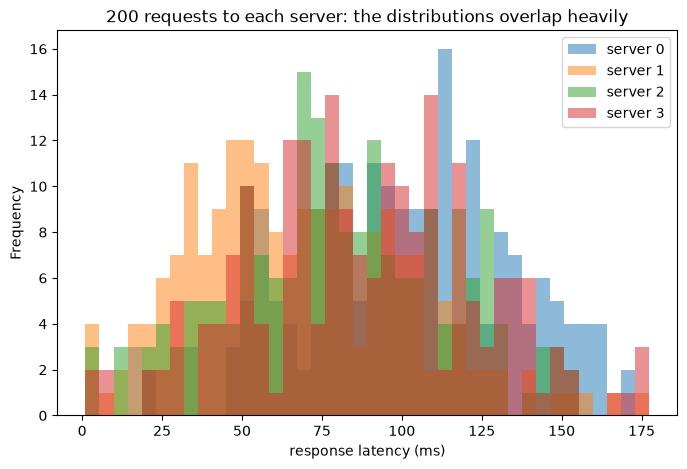

,server 0,server 1,server 2,server 3
mean,100.53,67.59,80.63,88.72
std,33.73,34.19,33.73,35.46
min,16.06,1.00,1.00,1.93
max,170.08,177.31,154.16,176.54


In [2]:
class ServerBandit:
    '''K servers with unknown latency distributions; reward is negative latency (ms).'''
    def __init__(self, latency_means, latency_std, rng):
        self.means = np.asarray(latency_means, dtype=float)   # hidden from the agent
        self.std = float(latency_std)
        self.rng = rng
        self.n_arms = len(self.means)

    def pull(self, arm):
        '''Send one request to server `arm`; return the reward (negative latency).'''
        latency = max(1.0, self.rng.normal(self.means[arm], self.std))
        return -latency

    def regret_of(self, arm):
        '''True expected regret of choosing `arm` (uses the hidden means; for evaluation only).'''
        return self.means[arm] - self.means.min()


LATENCY_MEANS = [100.0, 70.0, 80.0, 90.0]   # ms; server 1 is best
LATENCY_STD = 35.0

# a quick look at what the agent is up against: 200 requests to each server
rng = np.random.default_rng(SEED)
bandit = ServerBandit(LATENCY_MEANS, LATENCY_STD, rng)
samples = pd.DataFrame({f'server {a}': [-bandit.pull(a) for _ in range(200)] for a in range(bandit.n_arms)})
samples.plot.hist(bins=40, alpha=0.5)
plt.xlabel('response latency (ms)')
plt.title('200 requests to each server: the distributions overlap heavily')
plt.show()
samples.describe().loc[['mean', 'std', 'min', 'max']]

### Implement epsilon-greedy action selection

Write `select_action(Q, epsilon, rng)`. `Q` is an array with the current estimate of the mean reward of each arm; `rng` is a `numpy.random.Generator`. With probability `epsilon` return a uniformly random arm (use `rng.random()` to draw the coin and `rng.integers(len(Q))` for the arm); otherwise return the arm with the highest estimate. Return a Python `int`.

The stub below returns a random arm every time (that is, it behaves like $\epsilon = 1$), so the cells that follow run before you fill it in; the regret curves will all look alike until you do.

In [3]:
def select_action(Q, epsilon, rng):
    '''Epsilon-greedy: explore with probability epsilon, otherwise exploit the best estimate.
    Arguments:
      Q: array of estimated mean rewards, one per arm
      epsilon: exploration probability in [0, 1]
      rng: numpy.random.Generator
    Returns:
      the index of the chosen arm (int)
    '''
    # TODO: with probability epsilon return a random arm (rng.integers(len(Q)));
    #       otherwise return the arm with the largest estimate (np.argmax(Q)).
    # Placeholder: always explore. Replace it.
    return int(rng.integers(len(Q)))

### Run it

`run_bandit` plays one episode of `steps` requests with a given $\epsilon$, keeping a running mean $Q(a)$ for each arm (the incremental update $Q(a) \leftarrow Q(a) + \frac{1}{N(a)}\,(r - Q(a))$ is the same as averaging all rewards seen from $a$), and records the cumulative regret after every step. Because a single run is noisy, we average the regret curve over 50 independent runs for each $\epsilon \in \{0, 0.1, 0.3\}$ and also record how often each strategy ends up preferring the truly best server.

Note that $Q$ starts at zero while every reward is negative, so an arm that has never been tried looks better than any arm that has. Even the pure greedy strategy ($\epsilon = 0$) therefore tries each server once before it starts exploiting. What it does after that is the point of the discussion below.

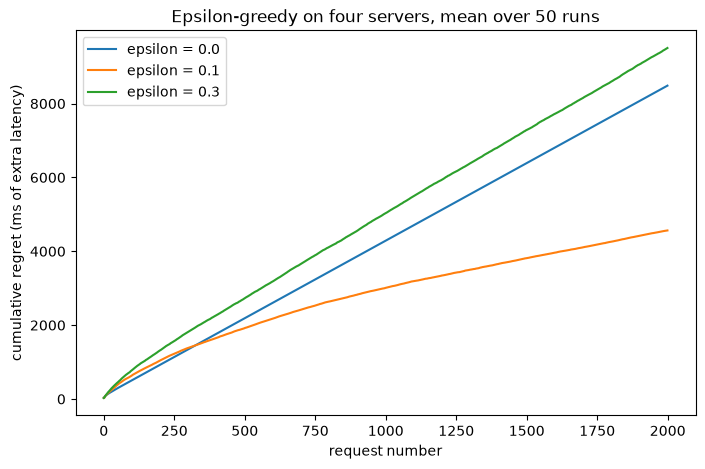

,regret after 2000 steps,runs that end up preferring the best server
epsilon,,
0.0,8486.0,0.62
0.1,4564.6,1.00
0.3,9505.8,1.00


In [5]:
def run_bandit(epsilon, steps=2000, seed=0):
    '''One run of epsilon-greedy on the server bandit.
    Returns the cumulative regret after each step and the final estimates Q.'''
    rng = np.random.default_rng(seed)
    bandit = ServerBandit(LATENCY_MEANS, LATENCY_STD, rng)
    Q = np.zeros(bandit.n_arms)        # estimated mean reward per arm
    N = np.zeros(bandit.n_arms)        # how many times each arm was pulled
    regret = np.zeros(steps)
    total = 0.0
    for t in range(steps):
        a = select_action(Q, epsilon, rng)
        r = bandit.pull(a)
        N[a] += 1
        Q[a] += (r - Q[a]) / N[a]      # running mean of the rewards from arm a
        total += bandit.regret_of(a)
        regret[t] = total
    return regret, Q


EPSILONS = [0.0, 0.1, 0.3]
N_RUNS = 50
STEPS = 2000

summary = []
for eps in EPSILONS:
    runs = [run_bandit(eps, STEPS, seed=s) for s in range(N_RUNS)]
    mean_regret = np.mean([r for r, _ in runs], axis=0)
    found_best = np.mean([np.argmax(Q) == np.argmin(LATENCY_MEANS) for _, Q in runs])
    plt.plot(mean_regret, label=f'epsilon = {eps}')
    summary.append({'epsilon': eps, 'regret after %d steps' % STEPS: mean_regret[-1],
                    'runs that end up preferring the best server': found_best})

plt.xlabel('request number')
plt.ylabel('cumulative regret (ms of extra latency)')
plt.title(f'Epsilon-greedy on four servers, mean over {N_RUNS} runs')
plt.legend()
plt.show()

pd.DataFrame(summary).set_index('epsilon')

**Discuss before moving on.**

* **Why does pure greedy ($\epsilon = 0$) get stuck?** After one sample from each server it commits to whichever happened to respond fastest, and from then on it only ever updates the estimate of the arm it keeps choosing. The other estimates are frozen at their single noisy sample, so nothing can ever change its mind. Look at the last column of the table: in a sizeable fraction of runs it is still preferring the wrong server after 2000 requests, and in those runs its regret grows linearly forever.
* **Why does the regret for $\epsilon > 0$ also keep growing?** A fixed $\epsilon$ means that a fixed fraction of requests go to random servers even after the estimates are accurate. The slope of each curve late in the run is roughly $\epsilon$ times the average gap to the best server. With $\epsilon = 0.3$, that eventually costs more than greedy's occasional mistake; the two curves cross.
* **What would you change?** Decaying $\epsilon$ over time, or an exploration bonus that depends on how often each arm has been tried (UCB), gets both: explore early, exploit later. The ABR agent in Part 3 uses a decaying $\epsilon$.

## Part 2: The environment: adaptive bitrate streaming as an MDP

In the bandit, choosing a server did not change which servers would be available next. In ABR streaming every decision changes the situation the next decision is made in: downloading a high-quality chunk on a slow link drains the buffer, and the next chunk then has to be chosen with a nearly empty buffer. That is a **Markov decision process** (MDP): a set of states $\mathcal{S}$, actions $\mathcal{A}$, a transition function that gives the next state from the current state and action, a reward $R(s, a, s')$, and a discount factor $\gamma$. For ABR:

| MDP component | In the video player |
|---|---|
| state $s$ | how many seconds of video are buffered, the throughput measured on the last download, and the bitrate of the last chunk |
| action $a$ | the bitrate of the next chunk: one of 300, 750, 1200, or 1850 kbps |
| transition | download the chunk at the network's current throughput; the buffer drains while the download runs and gains 4 seconds when it finishes; if it drains to zero, playback stalls (**rebuffering**) until the chunk arrives |
| reward $r$ | the chunk's contribution to **quality of experience (QoE)**, below |
| discount $\gamma$ | how much the agent cares about later chunks relative to the next one (set in Part 3) |

We use the QoE definition from Pensieve: for each chunk,

$$ r = \underbrace{q(a)}_{\text{bitrate utility, Mbps}} \;-\; \underbrace{4.3 \times \text{rebuffer seconds}}_{\text{stall penalty}} \;-\; \underbrace{1.0 \times |q(a) - q(a_{\text{prev}})|}_{\text{smoothness penalty}} .$$

The bitrate utility rewards quality, the rebuffer penalty makes a one-second stall cost about as much as 4.3 seconds of the highest quality buys, and the smoothness penalty discourages flickering between qualities.

**Throughput traces.** Real ABR work trains on recorded bandwidth traces. We synthesize ours: a mean-reverting random walk around 1.6 Mbps (so the throughput wanders but does not drift away), with occasional drops to a quarter of the current rate lasting a few chunks, which is what a cellular handoff or a competing download looks like to the player. One trace is for training. A set of 20 others, generated from different seeds, is held out for evaluation: a single 200-chunk session is one sample, and whether a policy happens to be mid-download at a high bitrate when that session's one big drop arrives can swing its score by a lot, so we report every policy's **mean over the held-out sessions** and plot its behavior on the first of them. Each trace is 200 chunks of 4 seconds, so an episode is one 13-minute session.

**Discretization.** Tabular Q-learning needs a finite, reasonably small state space. The environment reports its state as a tuple `(buffer_bucket, throughput_bucket, last_bitrate_index)`: the buffer level is bucketed at 4, 8, 12, and 20 seconds (5 buckets), the last measured throughput is bucketed at the four bitrate levels (5 buckets: below 300 kbps, 300 to 750, ..., above 1850), and the last bitrate is one of 4 levels. That is $5 \times 5 \times 4 = 100$ states and 4 actions, so the Q-table has 400 entries. `ABREnv.state_index` maps the tuple to a row number.

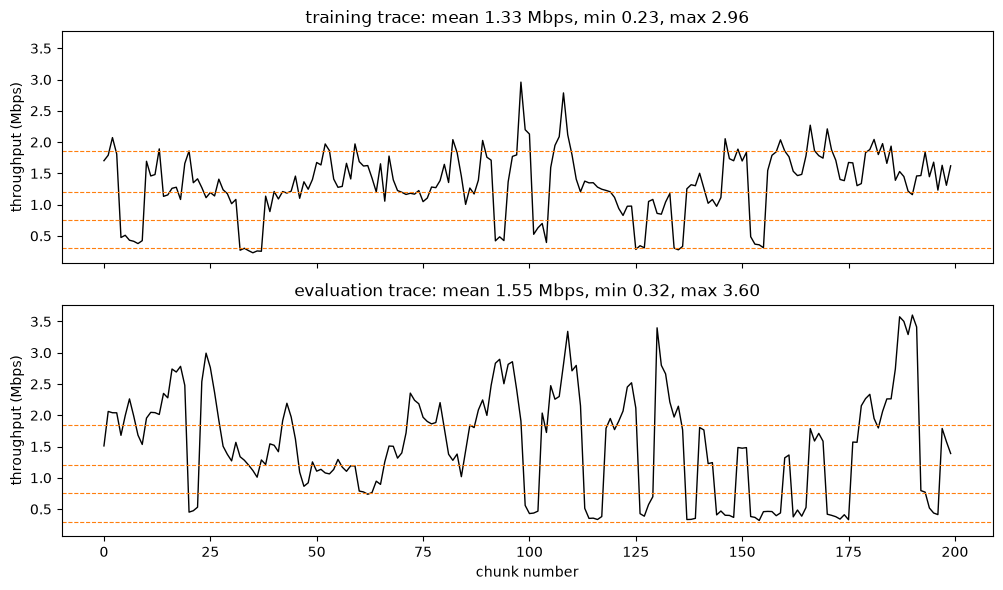

In [6]:
BITRATES_KBPS = np.array([300, 750, 1200, 1850])   # the four quality levels (actions 0..3)
CHUNK_SECONDS = 4.0                                 # every chunk holds 4 s of video


def make_trace(n_chunks, seed, mean_mbps=1.6, theta=0.15, sigma=0.18,
               drop_prob=0.06, drop_factor=0.25):
    '''Synthetic throughput trace (Mbps), one value per chunk download.
    log-throughput follows a mean-reverting random walk around log(mean_mbps);
    with probability drop_prob per chunk a drop begins that cuts throughput to
    drop_factor of its value for 3 to 6 chunks.'''
    rng = np.random.default_rng(seed)
    log_mu = np.log(mean_mbps)
    x = log_mu
    trace = np.empty(n_chunks)
    drop_left = 0
    for i in range(n_chunks):
        x = x + theta * (log_mu - x) + sigma * rng.normal()
        if drop_left == 0 and rng.random() < drop_prob:
            drop_left = int(rng.integers(3, 7))
        value = np.exp(x) * (drop_factor if drop_left > 0 else 1.0)
        if drop_left > 0:
            drop_left -= 1
        trace[i] = np.clip(value, 0.15, 6.0)
    return trace


N_CHUNKS = 200
train_trace = make_trace(N_CHUNKS, seed=1)                                   # the agent trains on this one
EVAL_TRACES = [make_trace(N_CHUNKS, seed=1000 + k) for k in range(20)]   # held out for evaluation
eval_trace = EVAL_TRACES[0]                                                  # the one we plot

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, sharey=True)
for ax, trace, name in zip(axes, [train_trace, eval_trace], ['training trace', 'evaluation trace']):
    ax.plot(trace, color='k', lw=1)
    for b in BITRATES_KBPS:
        ax.axhline(b / 1000, color='C1', ls='--', lw=0.8)
    ax.set_ylabel('throughput (Mbps)')
    ax.set_title(f'{name}: mean {trace.mean():.2f} Mbps, min {trace.min():.2f}, max {trace.max():.2f}')
axes[-1].set_xlabel('chunk number')
plt.tight_layout()
plt.show()

In [7]:
class ABREnv:
    '''A video session as an MDP.

    Each step downloads one 4-second chunk at the bitrate chosen by `action`
    (an index into BITRATES_KBPS) over the next throughput value of the trace.
    The playback buffer drains while the chunk downloads and gains 4 s when it
    arrives; it is capped at `buffer_cap` seconds (a real player stops
    downloading when it is full). If the buffer runs dry, the time until the
    chunk arrives is counted as rebuffering.

    State (returned by reset/step): a tuple
        (buffer_bucket, throughput_bucket, last_bitrate_index)
    with buffer bucketed at BUFFER_EDGES seconds and the last measured
    throughput bucketed at the bitrate levels. state_index() maps the tuple to
    an integer in range(n_states) for indexing a Q-table.

    Reward: Pensieve QoE for the chunk,
        bitrate (Mbps) - rebuf_penalty * rebuffer seconds
                       - smooth_penalty * |bitrate - previous bitrate| (Mbps).

    `noise` adds multiplicative log-normal jitter to each chunk's throughput
    (used during training so the agent sees varied conditions); the trace
    itself is replayed exactly when noise is 0.
    '''
    BUFFER_EDGES = np.array([4.0, 8.0, 12.0, 20.0])          # seconds
    THROUGHPUT_EDGES = BITRATES_KBPS / 1000.0                # Mbps

    def __init__(self, trace, buffer_cap=30.0, rebuf_penalty=4.3, smooth_penalty=1.0,
                 noise=0.0, seed=0):
        self.trace = np.asarray(trace, dtype=float)
        self.buffer_cap = float(buffer_cap)
        self.rebuf_penalty = float(rebuf_penalty)
        self.smooth_penalty = float(smooth_penalty)
        self.noise = float(noise)
        self.rng = np.random.default_rng(seed)
        self.n_actions = len(BITRATES_KBPS)
        self.n_buffer_buckets = len(self.BUFFER_EDGES) + 1
        self.n_throughput_buckets = len(self.THROUGHPUT_EDGES) + 1
        self.n_states = self.n_buffer_buckets * self.n_throughput_buckets * self.n_actions
        self.reset()

    # ----- state -----
    def _state(self):
        b = int(np.searchsorted(self.BUFFER_EDGES, self.buffer_s, side='right'))
        t = int(np.searchsorted(self.THROUGHPUT_EDGES, self.throughput_mbps, side='right'))
        return (b, t, self.last_action)

    def state_index(self, state):
        '''Row number of a state tuple in a Q-table of shape (n_states, n_actions).'''
        b, t, a = state
        return (b * self.n_throughput_buckets + t) * self.n_actions + a

    def describe_state(self, index):
        '''Inverse of state_index, for reading a Q-table.'''
        a = index % self.n_actions
        t = (index // self.n_actions) % self.n_throughput_buckets
        b = index // (self.n_actions * self.n_throughput_buckets)
        return (b, t, a)

    # ----- dynamics -----
    def reset(self):
        '''Start a new session: empty buffer, lowest quality, throughput probed from the trace.'''
        self.chunk = 0
        self.buffer_s = 0.0
        self.last_action = 0
        self.throughput_mbps = float(self.trace[0])
        return self._state()

    def step(self, action):
        '''Download the next chunk at BITRATES_KBPS[action].
        Returns (state, reward, done, info); info holds the continuous quantities.'''
        action = int(action)
        throughput = float(self.trace[self.chunk])
        if self.noise > 0:
            throughput *= float(np.exp(self.rng.normal(0.0, self.noise)))

        chunk_bits = BITRATES_KBPS[action] * 1000.0 * CHUNK_SECONDS
        download_s = chunk_bits / (throughput * 1e6)

        rebuffer_s = max(0.0, download_s - self.buffer_s)      # playback stalls if the buffer runs dry
        self.buffer_s = max(0.0, self.buffer_s - download_s) + CHUNK_SECONDS
        self.buffer_s = min(self.buffer_s, self.buffer_cap)    # a full buffer pauses downloading

        quality = BITRATES_KBPS[action] / 1000.0
        prev_quality = BITRATES_KBPS[self.last_action] / 1000.0
        reward = (quality
                  - self.rebuf_penalty * rebuffer_s
                  - self.smooth_penalty * abs(quality - prev_quality))

        self.throughput_mbps = throughput
        self.last_action = action
        self.chunk += 1
        done = self.chunk >= len(self.trace)

        info = {'bitrate_kbps': int(BITRATES_KBPS[action]), 'throughput_mbps': throughput,
                'download_s': download_s, 'rebuffer_s': rebuffer_s, 'buffer_s': self.buffer_s}
        return self._state(), reward, done, info


env = ABREnv(train_trace)
print(f'{env.n_states} states x {env.n_actions} actions = {env.n_states * env.n_actions} Q-table entries')
print('initial state (buffer bucket, throughput bucket, last bitrate index):', env.reset())
state, reward, done, info = env.step(2)   # download one chunk at 1200 kbps
print('after one chunk at 1200 kbps:', state, 'reward %.2f' % reward, info)

100 states x 4 actions = 400 Q-table entries
initial state (buffer bucket, throughput bucket, last bitrate index): (0, 3, 0)
after one chunk at 1200 kbps: (1, 3, 2) reward -11.82 {'bitrate_kbps': 1200, 'throughput_mbps': 1.7026890301742352, 'download_s': np.float64(2.8190702558933025), 'rebuffer_s': np.float64(2.8190702558933025), 'buffer_s': 4.0}


### Running a policy

A **policy** maps states to actions. To compare policies fairly we run each one over the same trace with the same environment and report the same four numbers: total QoE (the sum of rewards), mean bitrate, total rebuffering time, and the number of bitrate switches. `run_policy` plays one full episode and returns a per-chunk log; `summarize` reduces the log to those four numbers.

A policy here is any function `policy(state, env)` that returns an action index. We pass the environment as well as the discretized state so that heuristics can look at the continuous buffer level (`env.buffer_s`) and throughput (`env.throughput_mbps`), which is what real players do. The learning agent in Part 3 only looks at `state`. `evaluate` runs a policy on every held-out session and averages the four numbers (so rebuffering and switches are per session); the plots show the first session only.

Two baselines are provided:

* **Fixed lowest**: always 300 kbps. It almost never stalls and almost never scores.
* **Rate-based**: pick the highest bitrate that is at or below the throughput measured on the last download. This is what the earliest ABR players did, and it is what a supervised model that predicts throughput would amount to.

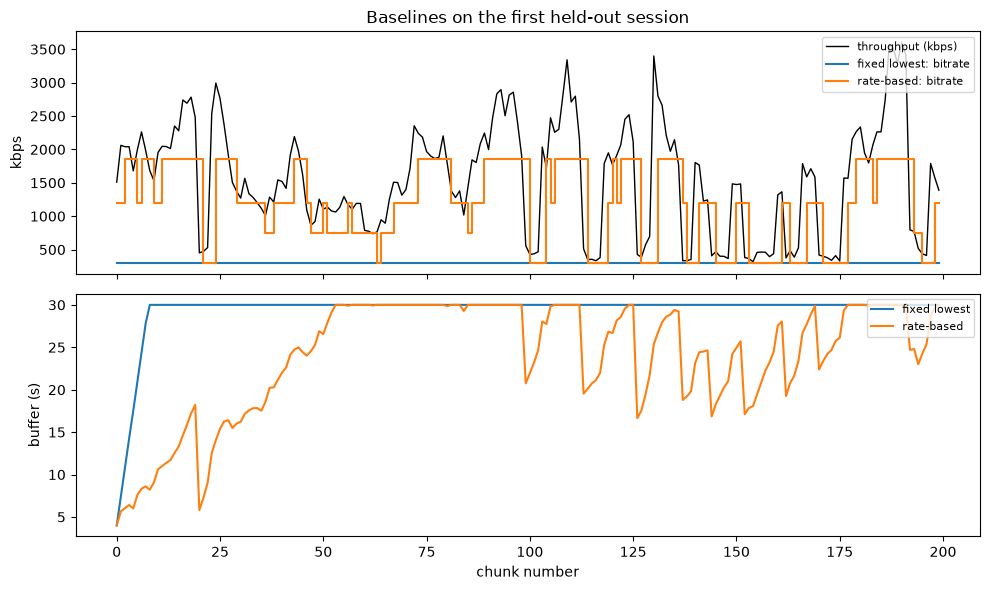

,total QoE,mean bitrate (kbps),rebuffer (s),switches
fixed lowest,55.48,300.0,1.05,0.00
rate-based,143.15,1112.3,8.29,63.55


In [8]:
def run_policy(env, policy):
    '''Play one episode of `env` under `policy(state, env) -> action`.
    Returns a DataFrame with one row per chunk.'''
    state = env.reset()
    done = False
    rows = []
    while not done:
        action = policy(state, env)
        state, reward, done, info = env.step(action)
        info['action'] = action
        info['reward'] = reward
        rows.append(info)
    return pd.DataFrame(rows)


def summarize(log):
    '''Total QoE, mean bitrate, total rebuffering, and number of bitrate switches of one episode.'''
    switches = int((log['action'].diff().fillna(0) != 0).sum())
    return {'total QoE': log['reward'].sum(),
            'mean bitrate (kbps)': log['bitrate_kbps'].mean(),
            'rebuffer (s)': log['rebuffer_s'].sum(),
            'switches': switches}


def evaluate(policy, rebuf_penalty=4.3, traces=None):
    '''Mean of summarize() over one episode on each held-out trace.'''
    traces = EVAL_TRACES if traces is None else traces
    rows = [summarize(run_policy(ABREnv(t, rebuf_penalty=rebuf_penalty), policy)) for t in traces]
    return pd.DataFrame(rows).mean()


def policy_lowest(state, env):
    '''Always the lowest bitrate.'''
    return 0


def policy_rate_based(state, env):
    '''Highest bitrate at or below the throughput measured on the last download.'''
    affordable = np.where(BITRATES_KBPS / 1000.0 <= env.throughput_mbps)[0]
    return int(affordable.max()) if len(affordable) else 0


def plot_episode(logs, trace, title=''):
    '''Bitrate chosen and buffer level over an episode, for one or more policies.'''
    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    axes[0].plot(trace * 1000, color='k', lw=1, label='throughput (kbps)')
    for name, log in logs.items():
        axes[0].step(log.index, log['bitrate_kbps'], where='post', label=f'{name}: bitrate')
        axes[1].plot(log['buffer_s'], label=name)
    axes[0].set_ylabel('kbps')
    axes[0].legend(loc='upper right', fontsize=8)
    axes[0].set_title(title)
    axes[1].set_ylabel('buffer (s)')
    axes[1].set_xlabel('chunk number')
    axes[1].legend(loc='upper right', fontsize=8)
    plt.tight_layout()
    plt.show()


baselines = {'fixed lowest': policy_lowest, 'rate-based': policy_rate_based}
logs = {name: run_policy(ABREnv(eval_trace), p) for name, p in baselines.items()}
plot_episode(logs, eval_trace, 'Baselines on the first held-out session')
pd.DataFrame({name: evaluate(p) for name, p in baselines.items()}).T

### Write a buffer-based heuristic

The rate-based policy reacts to the last measurement and nothing else: when throughput drops it has already requested a chunk it cannot afford, and when throughput is jittery it switches on every chunk. The buffer is a better signal, because it integrates the recent past: a full buffer means the player has been downloading faster than it plays and can afford to take risks; a nearly empty one means a stall is imminent regardless of what the last measurement said. Buffer-based ABR (the BBA family of algorithms) uses thresholds on the buffer level alone.

Write `policy_buffer_based(state, env)`: read the buffer level from `env.buffer_s` and return a higher bitrate index the fuller the buffer is. Start with three thresholds, for example 10, 16, and 22 seconds (below the first: 300 kbps; between the first and second: 750; and so on), then tune them. Remember that the buffer is capped at 30 seconds and a chunk adds 4 seconds, so the top threshold has to be reachable.

The stub returns the lowest bitrate, so the comparison cell runs (and shows the heuristic tied with "fixed lowest") until you replace it. Once it works, compare the three policies' total QoE and rebuffering time in the table.

In [9]:
def policy_buffer_based(state, env):
    '''Pick the bitrate from the buffer level alone (thresholds in seconds).'''
    buffer_s = env.buffer_s
    # TODO: return 0, 1, 2, or 3 depending on which thresholds buffer_s exceeds,
    #       e.g. below 10 s -> 0, below 16 s -> 1, below 22 s -> 2, otherwise 3.
    # Placeholder: always the lowest bitrate. Replace it.
    return 0

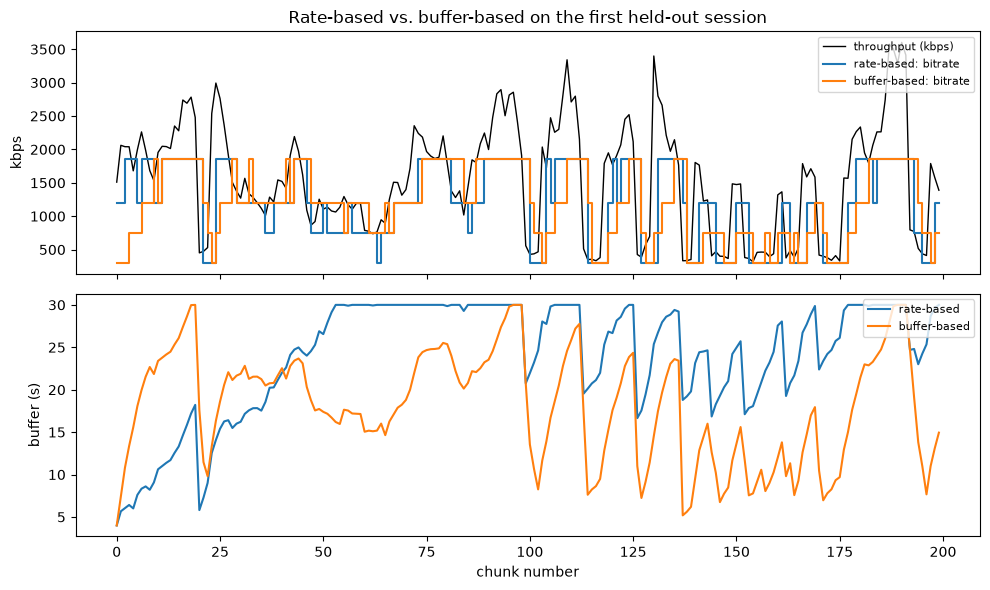

,total QoE,mean bitrate (kbps),rebuffer (s),switches
fixed lowest,55.48,300.00,1.05,0.00
rate-based,143.15,1112.30,8.29,63.55
buffer-based,156.50,1147.06,8.94,60.85


In [11]:
heuristics = {'fixed lowest': policy_lowest,
              'rate-based': policy_rate_based,
              'buffer-based': policy_buffer_based}

logs = {name: run_policy(ABREnv(eval_trace), p) for name, p in heuristics.items()}
plot_episode({k: logs[k] for k in ['rate-based', 'buffer-based']}, eval_trace,
             'Rate-based vs. buffer-based on the first held-out session')
heuristic_table = pd.DataFrame({name: evaluate(p) for name, p in heuristics.items()}).T
heuristic_table

Look at where each heuristic loses points. The rate-based player stalls when a drop arrives while it is mid-download at a high bitrate, and it switches constantly because it tracks every wiggle in the measurement; the buffer-based player spends the first several chunks at low quality while it fills the buffer, and it stalls when a long drop outlasts the buffer it built. Neither looks at both signals. The agent in the next part is given both, plus the last bitrate, and has to work out from reward alone how to use them.

## Part 3: Q-learning

The **Q-function** $Q(s, a)$ is the expected total discounted reward from taking action $a$ in state $s$ and acting optimally afterwards. If we knew it, the optimal policy would be trivial: in state $s$ take $\arg\max_a Q(s, a)$. **Q-learning** estimates it from experience without a model of the environment. After taking action $a$ in state $s$, receiving reward $r$, and arriving in state $s'$, the agent nudges its estimate toward the Bellman target:

$$ Q(s, a) \leftarrow Q(s, a) + \alpha \Big[\, r + \gamma \max_{a'} Q(s', a') - Q(s, a) \,\Big] $$

The quantity in brackets is the **temporal-difference error**: what the agent now thinks the value of $(s, a)$ should be (the reward it just got plus the discounted value of the best thing it can do next) minus what it thought before. $\alpha$ is the learning rate and $\gamma$ the discount factor. With a table of 100 states and 4 actions, this is one line of `numpy`.

During training the agent picks actions epsilon-greedily over the table, exactly as in Part 1 but with the row of the Q-table for the current state in place of the bandit's single row of estimates, and $\epsilon$ decays from 1 (pure exploration) toward a small floor as training proceeds. At evaluation time we switch exploration off and act greedily.

### Implement the update and the policy

Write the two functions below. `Q` is a `numpy` array of shape `(n_states, n_actions)` and the states are integer row indices (the training loop converts the environment's state tuple with `env.state_index`).

* `q_update(Q, s, a, r, s_next, alpha, gamma)` applies the update above **in place** (modify `Q[s, a]`; return nothing).
* `epsilon_greedy(Q, s, epsilon, rng)` returns a random action with probability `epsilon` and otherwise `argmax` of row `s`. It is `select_action` from Part 1 applied to `Q[s]`.

The stubs leave the table at zero and act randomly, so the training cell runs but learns nothing until you fill them in.

In [12]:
def q_update(Q, s, a, r, s_next, alpha, gamma):
    '''One Q-learning update of Q[s, a] in place, from the transition (s, a, r, s_next).'''
    # TODO: td_target = r + gamma * max_a' Q[s_next, a']
    #       Q[s, a] += alpha * (td_target - Q[s, a])
    pass   # placeholder: no learning. Replace it.


def epsilon_greedy(Q, s, epsilon, rng):
    '''Epsilon-greedy action from row s of the Q-table.'''
    # TODO: with probability epsilon return rng.integers(Q.shape[1]);
    #       otherwise return the argmax of Q[s]. Return an int.
    return int(rng.integers(Q.shape[1]))   # placeholder: always explore. Replace it.

### Train

The loop below is provided. Each episode replays the training trace from the start with 10% multiplicative throughput jitter (`noise=0.1`), so the agent sees a slightly different session every time rather than memorizing one. Two things decay geometrically over the first 80% of training and then hold: $\epsilon$, from 1.0 to 0.05, so the agent explores early and exploits late; and the learning rate $\alpha$, from 0.3 to 0.01, so that early experience moves the estimates quickly but a single unlucky stall late in training (one chunk can score $-40$) cannot overturn an estimate built from hundreds of samples. Without the second schedule the greedy policy changes noticeably from one training run to the next. The learning curve plots each episode's total QoE (collected while still exploring, so it is noisier and lower than the greedy policy would score) and a 50-episode moving average.

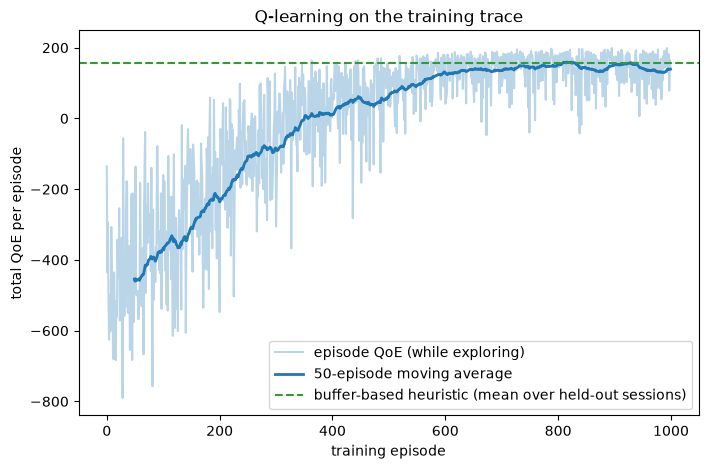

78 of 100 states were visited during training


In [14]:
def train_q_learning(env, episodes=1000, gamma=0.9,
                     alpha_start=0.3, alpha_end=0.01, eps_start=1.0, eps_end=0.05, seed=0):
    '''Tabular Q-learning on `env`. Returns the Q-table and the per-episode total reward.'''
    rng = np.random.default_rng(seed)
    Q = np.zeros((env.n_states, env.n_actions))
    # both schedules reach their floor at 80% of training and hold there
    eps_decay = (eps_end / eps_start) ** (1.0 / (0.8 * episodes))
    alpha_decay = (alpha_end / alpha_start) ** (1.0 / (0.8 * episodes))
    epsilon, alpha = eps_start, alpha_start
    episode_reward = np.zeros(episodes)
    for ep in range(episodes):
        s = env.state_index(env.reset())
        done = False
        total = 0.0
        while not done:
            a = epsilon_greedy(Q, s, epsilon, rng)
            state_next, r, done, _ = env.step(a)
            s_next = env.state_index(state_next)
            q_update(Q, s, a, r, s_next, alpha, gamma)
            s = s_next
            total += r
        episode_reward[ep] = total
        epsilon = max(eps_end, epsilon * eps_decay)
        alpha = max(alpha_end, alpha * alpha_decay)
    return Q, episode_reward


GAMMA, EPISODES = 0.9, 1000

train_env = ABREnv(train_trace, noise=0.1, seed=SEED)
Q, learning_curve = train_q_learning(train_env, episodes=EPISODES, gamma=GAMMA, seed=3)

plt.plot(learning_curve, color='C0', alpha=0.3, label='episode QoE (while exploring)')
plt.plot(pd.Series(learning_curve).rolling(50).mean(), color='C0', lw=2, label='50-episode moving average')
plt.axhline(heuristic_table.loc['buffer-based', 'total QoE'], color='C2', ls='--',
            label='buffer-based heuristic (mean over held-out sessions)')
plt.xlabel('training episode')
plt.ylabel('total QoE per episode')
plt.title('Q-learning on the training trace')
plt.legend()
plt.show()

visited = (Q != 0).any(axis=1).sum()
print(f'{visited} of {Q.shape[0]} states were visited during training')

### Evaluate on the held-out sessions

`policy_from_q` turns the table into a greedy policy. We run it on the 20 held-out sessions, none of which the agent has seen, under the same environment (no jitter) as the heuristics, and put all four policies in one table of per-session means. The plot shows the first held-out session.

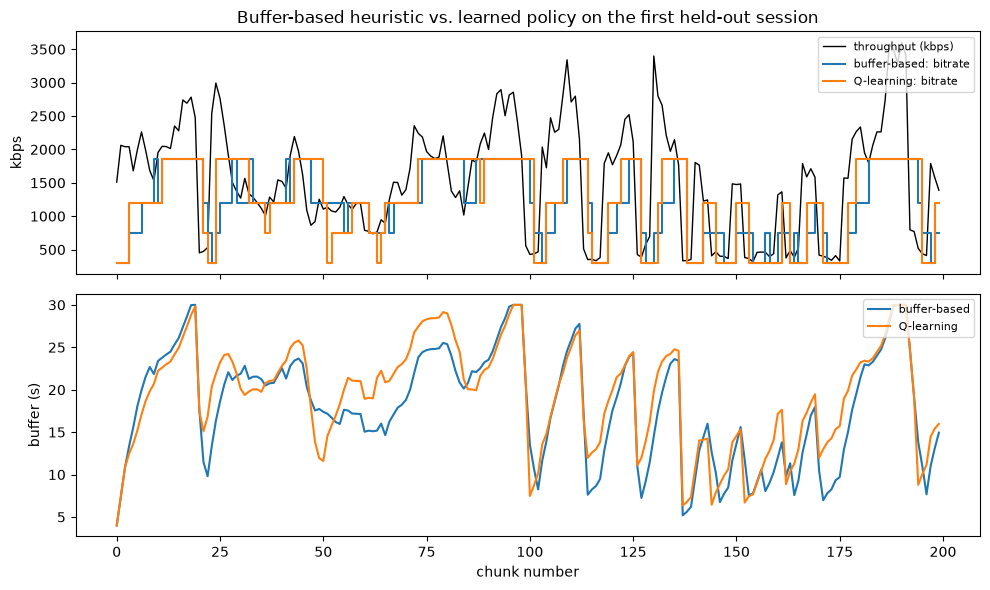

,total QoE,mean bitrate (kbps),rebuffer (s),switches
fixed lowest,55.48,300.00,1.05,0.00
rate-based,143.15,1112.30,8.29,63.55
buffer-based,156.50,1147.06,8.94,60.85
Q-learning,176.74,1175.47,6.59,43.15


In [15]:
def policy_from_q(Q):
    '''Greedy policy: in each state take the action with the largest Q-value.'''
    def policy(state, env):
        return int(np.argmax(Q[env.state_index(state)]))
    return policy


policies = dict(heuristics)
policies['Q-learning'] = policy_from_q(Q)

logs = {name: run_policy(ABREnv(eval_trace), p) for name, p in policies.items()}
plot_episode({k: logs[k] for k in ['buffer-based', 'Q-learning']}, eval_trace,
             'Buffer-based heuristic vs. learned policy on the first held-out session')
evaluation_table = pd.DataFrame({name: evaluate(p) for name, p in policies.items()}).T
evaluation_table

### What did it learn?

A Q-table can be read. The cell below prints the greedy action for every (buffer bucket, throughput bucket) when the last chunk was 750 kbps. Rows are buffer levels, columns are the throughput measured on the last download; entries are the bitrate the agent would request next (a dash marks a state that was never visited, where the table is still all zeros and the argmax is arbitrary). Compare it with the two heuristics: a rate-based policy would be constant down each column, a buffer-based one constant across each row.

In [16]:
def policy_table(Q, env, last_action=1):
    buffer_labels = ['< 4 s', '4-8 s', '8-12 s', '12-20 s', '> 20 s']
    tp_labels = ['< 300', '300-750', '750-1200', '1200-1850', '> 1850']
    table = pd.DataFrame(index=buffer_labels, columns=tp_labels, dtype=object)
    for b in range(env.n_buffer_buckets):
        for t in range(env.n_throughput_buckets):
            row = Q[env.state_index((b, t, last_action))]
            table.iloc[b, t] = '-' if not row.any() else int(BITRATES_KBPS[np.argmax(row)])
    table.index.name = 'buffer'
    table.columns.name = 'last throughput (kbps)'
    return table


print(f'Greedy bitrate (kbps) after a {BITRATES_KBPS[1]} kbps chunk:')
policy_table(Q, train_env, last_action=1)

Greedy bitrate (kbps) after a 750 kbps chunk:


last throughput (kbps),< 300,300-750,750-1200,1200-1850,> 1850
buffer,,,,,
< 4 s,-,-,-,-,-
4-8 s,300,300,750,750,750
8-12 s,300,300,300,750,750
12-20 s,300,300,750,750,750
> 20 s,750,750,1200,1200,1850


### Change the reward and retrain

The agent optimizes whatever we write down, and nothing else. Raise the rebuffer penalty from 4.3 to 10 (so one second of stall now costs more than five seconds of top quality is worth), retrain with everything else unchanged, and evaluate the new greedy policy on the held-out sessions. Compare the two learned policies' mean bitrate, rebuffering time, and switches side by side. A total QoE is only comparable between policies scored under the *same* reward, so score both policies at 4.3 (and, if you like, both at 10): `evaluate` takes the penalty as an argument, and a greedy policy does not depend on it.

The stub does nothing; the cell runs but prints no comparison until you fill it in.

In [17]:
REBUF_PENALTY_HIGH = 10.0

# TODO: 1. build a training environment with rebuf_penalty=REBUF_PENALTY_HIGH (keep noise=0.1)
#          and train a second Q-table with the same GAMMA, EPISODES and seed.
#       2. evaluate(policy_from_q(Q_high)) and evaluate(policy_from_q(Q)) on the held-out sessions
#       3. put the two in one DataFrame and compare mean bitrate, rebuffer (s), and switches;
#          add a column with each policy's QoE scored at the other penalty to compare QoE.
Q_high = None

With the harsher penalty the agent requests lower bitrates and stalls less. Nobody told it to be conservative; the 10 did. Look at the two QoE columns, too: each policy should score best under the reward it was trained for, and when a policy trained at 4.3 loses even at 4.3 (which happens on some training runs), that is the rare, expensive stall it did not see often enough during training to learn to avoid. The reward definition *is* the specification, and a few hundred episodes is a small sample of the rare events in it. Keep your numbers for Part 4.

## Part 4: Questions to answer in your notes

Write a few sentences on each. No code is needed.

1. **Discretization.** The agent never saw the actual buffer level or throughput, only which of a handful of buckets each fell into. Why does this matter for tabular Q-learning, and what specifically would break if we fed it the continuous values instead? What would you need to change in the algorithm (not just the table size) to handle a continuous state, and what does the lecture's treatment of deep Q-networks replace the table with?

2. **Sim-to-real.** List two things the agent could have learned from `ABREnv` that would not carry over to a real video player on a real network. Think about what the simulator leaves out (how the trace was made, what the player observes, what the downloads do to the network) and about what the agent might have memorized about the training trace. Puffer's deployment of RL-trained ABR to real viewers found that simulation gains largely disappeared in the field; which of your two items is closest to their explanation?

3. **Reward design.** A bad reward produces a bad policy, not an error message. Using the numbers from your Part 3 runs, give one concrete example of how changing the reward changed the behavior (the rebuffer penalty experiment, or a change you made yourself, such as dropping the smoothness term or raising the bitrate utility). Then describe a reward that *looks* reasonable for ABR but that an agent could satisfy while making viewers miserable.

4. **Other formulations.** RL has been applied to congestion control, packet scheduling, and routing. Pick one and write down the MDP: what is in the state, what the actions are, what the reward is, and over what timescale a step happens. Then name the one part of your formulation you are least sure of and why (for example, whether the reward can be measured by the agent that needs it, or whether the state satisfies the Markov property).